# Allocating risk by recursive bisection

This native Julia companion preserves the equations, public data, portfolio rules, chronological windows and original seeds. Fixed standard-normal innovations preserve the original NumPy streams. Coordinate signs specify only the SVD orientation of the declared known covariance designs; Julia computes the factors, samples, trees, allocations and results. Figures use the requested dark theme and outputs are saved under `outputs/julia`.

The variance assigned to a cluster is computed from an inverse-variance portfolio inside that cluster:

$$
\widetilde w_i^{(C)}=\frac{\sigma_i^{-2}}{\sum_{j\in C}\sigma_j^{-2}},
\qquad
V_C=(\widetilde w^{(C)})^{\mathsf T}\Sigma_C\widetilde w^{(C)}.
$$

Here, $C$ is a cluster, $i$ and $j$ label assets in that cluster, $\sigma_i^2$ is asset $i$'s variance, $\widetilde w_i^{(C)}$ is its internal inverse-variance weight, $\Sigma_C$ is the cluster covariance matrix, $V_C$ is cluster variance, and $\mathsf T$ denotes transpose.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("25_hierarchical_risk_parity");
using CSV, TOML, Printf
default(left_margin=10Plots.mm,bottom_margin=8Plots.mm)
include(joinpath("..","support","BookHierarchy.jl"))
using .BookHierarchy
using RiskLabAI.Optimization: cluster_variance,hrp,inverse_variance_weights,recursive_bisection
violet = "#C084FC"
table(frame,name,caption) = save_table(frame,paths,name;caption,label="tab:chapter21-"*replace(name,"_"=>"-"))
matrix_data(values) = DataFrame(values,:auto)
data_path = dataset_path("french_49_industries")
@assert isfile(data_path)
lines = readlines(data_path)
first_row = findfirst(line->startswith(line,",Agric"),lines)
last_row = findnext(line->isempty(strip(line)),lines,first_row+1)
raw = CSV.read(IOBuffer(join(lines[first_row:last_row-1],"\n")),DataFrame)
all_dates = Date.(string.(raw[!,1]),dateformat"yyyymmdd")
all_values = Matrix{Float64}(raw[:,2:end])
valid = (Date(2019,1,1).<=all_dates).&(all_dates.<=Date(2025,12,31)).&vec(all(all_values.>-99;dims=2))
dates = all_dates[valid]
selected_assets = names(raw)[2:17]
public_sample = all_values[valid,1:16]/100
annual_covariance,public_correlation = cov(public_sample)*252,cor(public_sample)
function matrix_panel(values,labels,title;limits=nothing,color=:magma)
    n = length(labels)
    return heatmap(1:n,1:n,values;title,color,clims=isnothing(limits) ? extrema(values) : limits,yflip=true,xticks=(1:n,labels),yticks=(1:n,labels),xrotation=90,tickfontsize=7,xlims=(0.5,n+0.5),ylims=(0.5,n+0.5),widen=false)
end
function tree_panel(tree,order,labels,title)
    n = length(labels)
    positions,heights = zeros(2n-1),zeros(2n-1)
    positions[order] = 1:n
    figure = plot(;title,xlim=(0.3,n+0.7),ylim=(0,1.08*maximum(tree[:,3])),xticks=(1:n,labels[order]),xrotation=90,tickfontsize=7,ylabel="Merge distance",legend=false)
    for step in axes(tree,1)
        left,right = Int.(tree[step,1:2]).+1
        height = tree[step,3]
        plot!(figure,[positions[left],positions[left],positions[right],positions[right]],[heights[left],height,height,heights[right]];color=palette.cyan)
        positions[n+step],heights[n+step] = (positions[left]+positions[right])/2,height
    end
    return figure
end
path_length(distance,order) = sum(distance[order[i],order[i+1]] for i in 1:length(order)-1)
turnover(a,b) = 0.5*sum(abs,a-b)
finite_mean(values) = mean(filter(isfinite,values))
provenance = DataFrame("Field"=>["Archive","Provider","Return type","Analysis start","Analysis end","Complete dates","Selected industries"],"Value"=>["49_Industry_Portfolios_daily_CSV.zip","Kenneth R. French Data Library","Daily value-weighted return",string(first(dates)),string(last(dates)),string(length(dates)),string(length(selected_assets))])
table(provenance,"allocation_data_provenance","Public data used for the Chapter 21 allocation study.")
_,single_tree,single_order = hierarchy(public_correlation)
function traced_bisection(covariance,order,labels)
    weights = ones(length(order))
    active,records,depth = [order],NamedTuple[],0
    while !isempty(active)
        children = Vector{Int}[]
        for cluster in active
            length(cluster)>1 || continue
            midpoint = length(cluster)÷2
            append!(children,[cluster[1:midpoint],cluster[midpoint+1:end]])
        end
        active = children
        isempty(active) && break
        depth += 1
        for position in 1:2:length(active)
            left,right = active[position:position+1]
            lv,rv = cluster_variance(covariance,left),cluster_variance(covariance,right)
            fraction = lv+rv==0 ? 0.5 : rv/(lv+rv)
            push!(records,(depth=depth,pair=(position+1)÷2,left=join(labels[left],", "),right=join(labels[right],", "),left_assets=length(left),right_assets=length(right),left_variance=lv,right_variance=rv,left_fraction=fraction,right_fraction=1-fraction,incoming=weights[first(left)]))
            weights[left] .*= fraction
            weights[right] .*= 1-fraction
        end
    end
    frame = DataFrame(records)
    rename!(frame,["Depth","Pair","Left cluster","Right cluster","Left assets","Right assets","Left variance","Right variance","Left fraction","Right fraction","Incoming multiplier"])
    return weights,frame
end
traced_weights,branch_allocations = traced_bisection(annual_covariance,single_order,selected_assets)
released_weights = hrp(annual_covariance,public_correlation)
direct_weights = ordered_weights(annual_covariance,single_order)
table(branch_allocations,"branch_allocations","Every recursive split in the public HRP allocation.")


8×2 DataFrame
 Row │ Field                Value
     │ String               String
─────┼────────────────────────────────────────────────────────
   1 │ Archive              49_Industry_Portfolios_daily_CSV…
   2 │ Provider             Kenneth R. French Data Library
   3 │ Return type          Daily value-weighted return
   4 │ Analysis start       2019-01-02
   5 │ Analysis end         2025-12-31
   6 │ Complete dates       1760
   7 │ Selected industries  16

Row,Depth,Pair,Left cluster,Right cluster,Left assets,Right assets,Left variance,Right variance,Left fraction,Right fraction,Incoming multiplier
,Int64,Int64,String,String,Int64,Int64,Float64,Float64,Float64,Float64,Float64
1,1,1,"Smoke, Fun, Hshld, Soda, Food, Beer, Toys, Agric","Clths, Txtls, Rubbr, Books, Chems, Drugs, Hlth, MedEq",8,8,0.0266445,0.0388534,0.593201,0.406799,1.0
2,2,1,"Smoke, Fun, Hshld, Soda","Food, Beer, Toys, Agric",4,4,0.0281069,0.0293781,0.511056,0.488944,0.593201
3,2,2,"Clths, Txtls, Rubbr, Books","Chems, Drugs, Hlth, MedEq",4,4,0.0541555,0.0360811,0.39985,0.60015,0.406799
4,3,1,"Smoke, Fun","Hshld, Soda",2,2,0.0411669,0.030111,0.422445,0.577555,0.303159
5,3,2,"Food, Beer","Toys, Agric",2,2,0.0292363,0.0687826,0.701728,0.298272,0.290042
6,3,3,"Clths, Txtls","Rubbr, Books",2,2,0.0904741,0.0478171,0.345771,0.654229,0.162659
7,3,4,"Chems, Drugs","Hlth, MedEq",2,2,0.0343707,0.047275,0.579026,0.420974,0.24414
8,4,1,Smoke,Fun,1,1,0.0499297,0.0941179,0.65338,0.34662,0.128068
9,4,2,Hshld,Soda,1,1,0.0332219,0.0366583,0.524588,0.475412,0.175091


## Split Fractions

A parent cluster is split so that the lower-variance child receives the larger fraction:

$$
\alpha_A=1-\frac{V_A}{V_A+V_B}=\frac{V_B}{V_A+V_B},
\qquad
w_i\leftarrow\alpha_Aw_i\ (i\in A),
\qquad
w_j\leftarrow(1-\alpha_A)w_j\ (j\in B).
$$

Here, $A$ and $B$ are sibling clusters, $V_A$ and $V_B$ are their cluster variances, $\alpha_A$ is the fraction assigned to cluster $A$, and $w_i$ and $w_j$ are the running asset weights multiplied at that split.

Row,Industry,HRP,Inverse variance,Equal weight,Minimum variance
,String,Float64,Float64,Float64,Float64
1,Agric,0.0513111,0.0393879,0.0625,0.0423513
2,Beer,0.0849701,0.084592,0.0625,-0.158299
3,Books,0.0524722,0.0543097,0.0625,0.127191
4,Chems,0.0512512,0.0545171,0.0625,-0.167604
5,Clths,0.0347377,0.0357975,0.0625,-0.031791
6,Drugs,0.0901125,0.0958548,0.0625,0.310104
7,Food,0.11856,0.118033,0.0625,0.489942
8,Fun,0.0443909,0.0350583,0.0625,0.0743155
9,Hlth,0.046918,0.0557026,0.0625,-0.0147137


Row,Portfolio,Annual volatility,Largest weight,Smallest weight,Gross exposure,Weight concentration,Effective holdings
,String,Float64,Float64,Float64,Float64,Float64,Float64
1,HRP,0.16989,0.11856,0.0215049,1.0,0.0728872,13.7198
2,Inverse variance,0.169625,0.118033,0.022161,1.0,0.0744322,13.4351
3,Equal weight,0.185824,0.0625,0.0625,1.0,0.0625,16.0
4,Minimum variance,0.147925,0.489942,-0.167604,1.95891,0.472836,2.1149


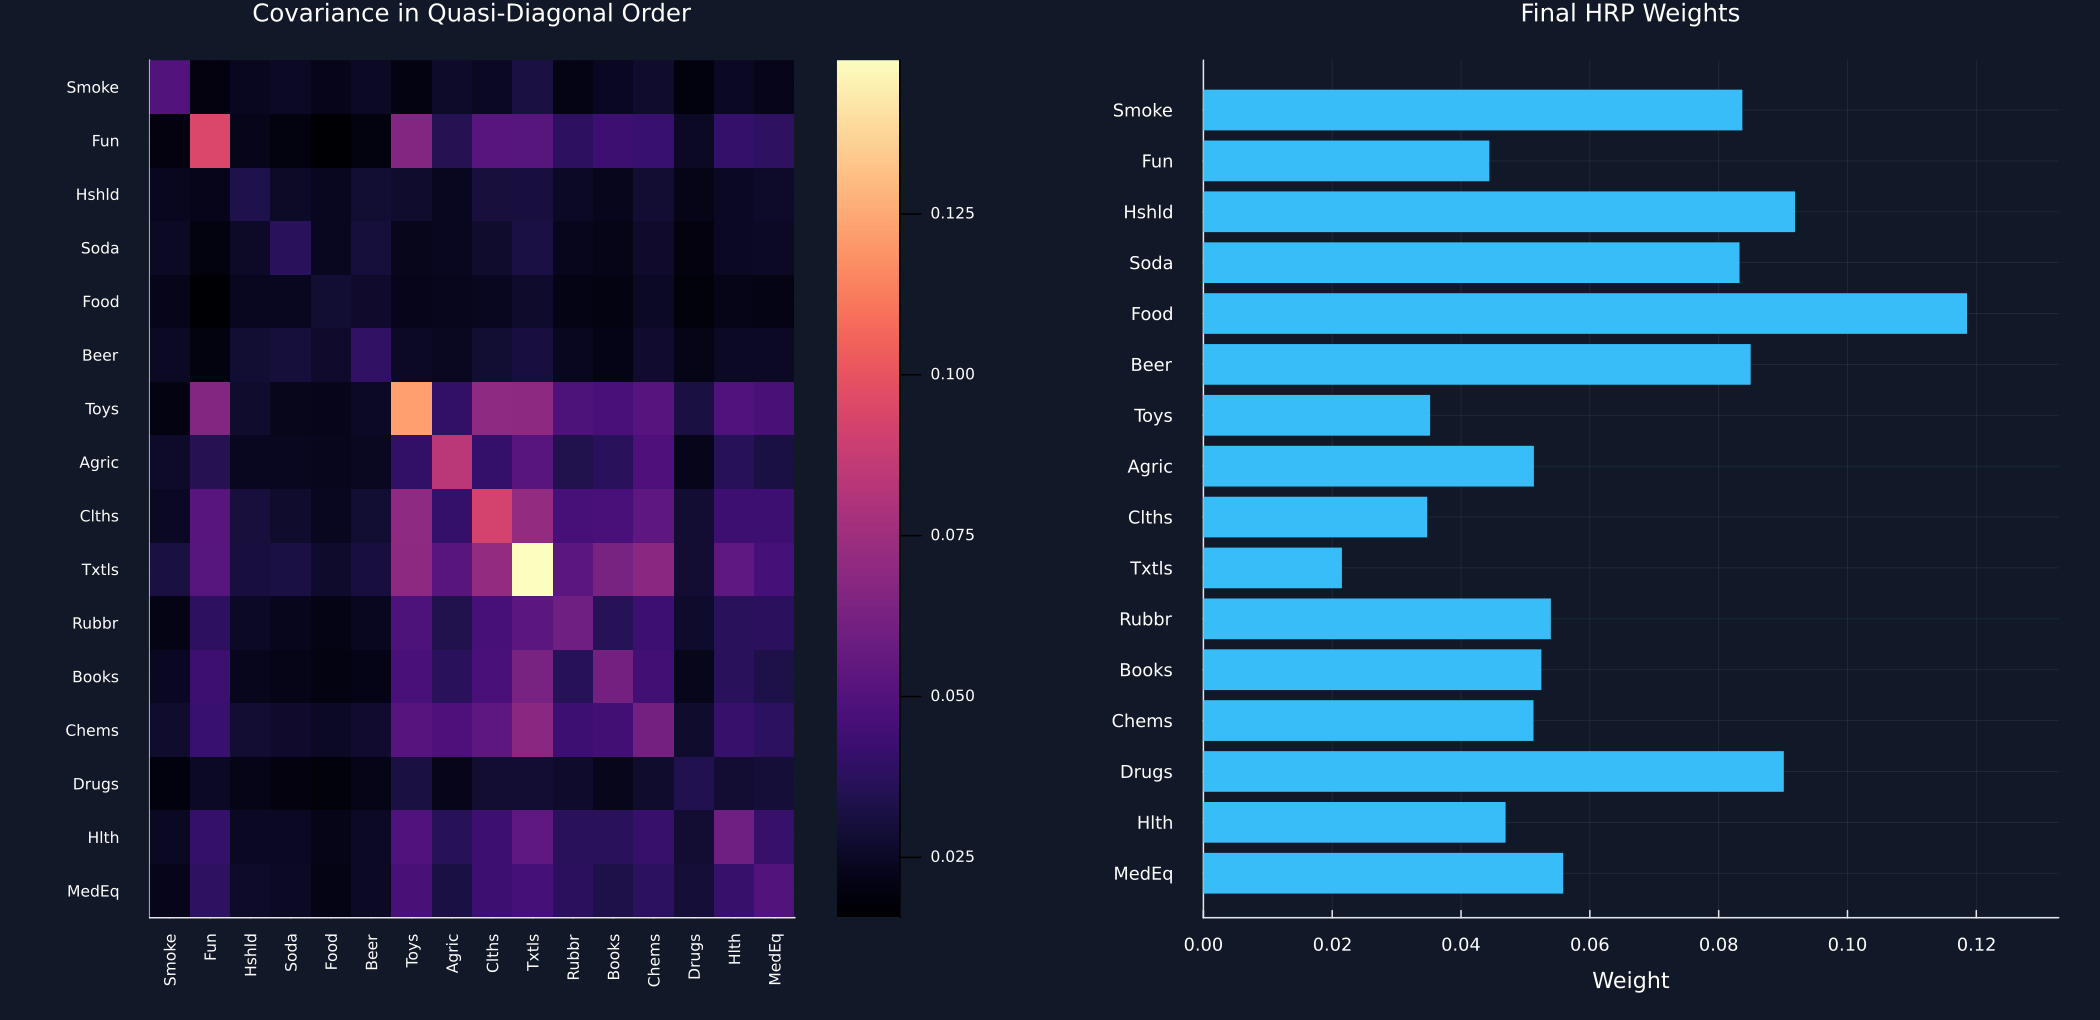

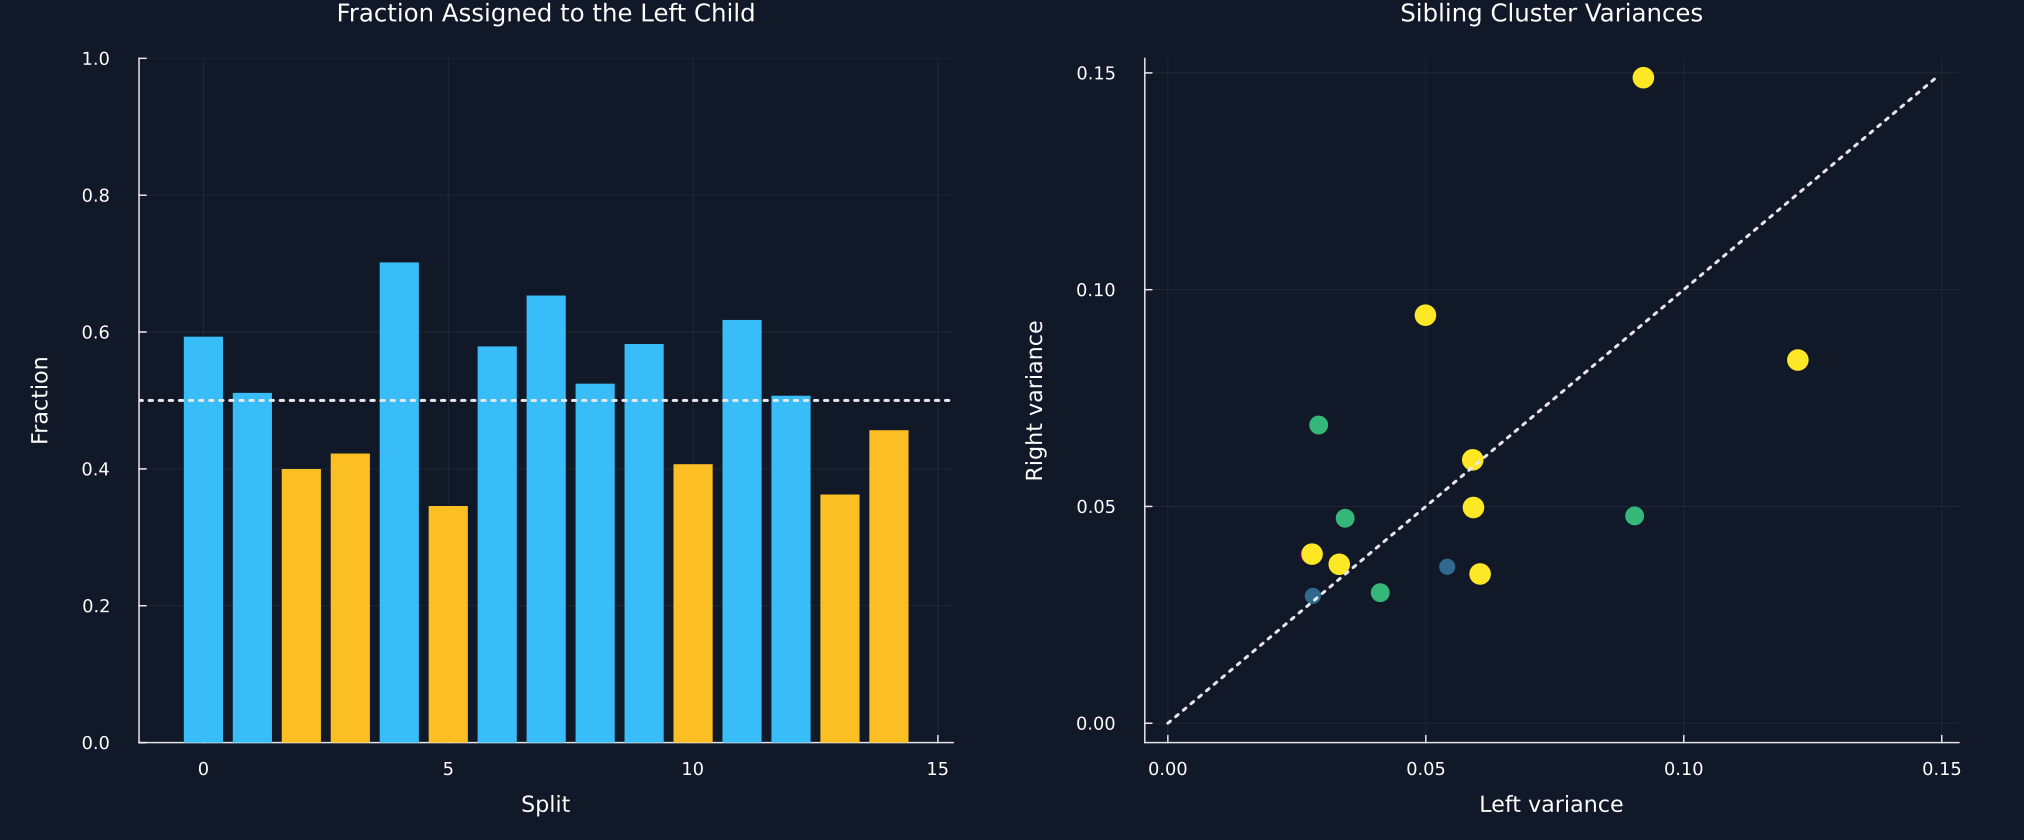

In [2]:
fitted_map = Dict(portfolio_set(annual_covariance,public_correlation))
method_names = ["HRP","Inverse variance","Equal weight","Minimum variance"]
method_colors = [palette.cyan,palette.amber,palette.green,palette.rose]
asset_sort = sortperm(selected_assets)
weight_table = DataFrame("Industry"=>selected_assets[asset_sort])
summary_rows = NamedTuple[]
for method in method_names
    weights = fitted_map[method]
    weight_table[!,method] = weights[asset_sort]
    push!(summary_rows,(Portfolio=method,volatility=sqrt(dot(weights,annual_covariance*weights)),largest=maximum(weights),smallest=minimum(weights),gross=sum(abs,weights),concentration=sum(abs2,weights),effective=1/sum(abs2,weights)))
end
portfolio_summary = DataFrame(summary_rows)
rename!(portfolio_summary,["Portfolio","Annual volatility","Largest weight","Smallest weight","Gross exposure","Weight concentration","Effective holdings"])
table(weight_table,"public_portfolio_weights","Public-sample weights for four portfolio rules.")
table(portfolio_summary,"public_portfolio_summary","Public-sample portfolio summaries.")
save_data(matrix_data(annual_covariance),paths,"annual_covariance")
p1 = matrix_panel(annual_covariance[single_order,single_order],selected_assets[single_order],"Covariance in Quasi-Diagonal Order")
p2 = bar(1:16,released_weights[single_order];orientation=:h,yflip=true,yticks=(1:16,selected_assets[single_order]),color=palette.cyan,linealpha=0,legend=false,xlabel="Weight",title="Final HRP Weights",xlims=(0,1.12*maximum(released_weights)))
save_figure(plot(p1,p2;layout=(1,2),size=(1400,680)),paths,"ordered_covariance_hrp_weights")
p1 = bar(0:14,branch_allocations[!,"Left fraction"];color=[value>=0.5 ? palette.cyan : palette.amber for value in branch_allocations[!,"Left fraction"]],linealpha=0,legend=false,title="Fraction Assigned to the Left Child",xlabel="Split",ylabel="Fraction",ylims=(0,1))
hline!(p1,[0.5];color=palette.text,linestyle=:dot,label=false)
p2 = scatter(branch_allocations[!,"Left variance"],branch_allocations[!,"Right variance"];marker_z=branch_allocations.Depth,markersize=4 .+branch_allocations.Depth,markercolor=:viridis,markerstrokewidth=0,legend=false,colorbar_title="Depth",title="Sibling Cluster Variances",xlabel="Left variance",ylabel="Right variance")
limit = maximum(Matrix(branch_allocations[:,["Left variance","Right variance"]]))
plot!(p2,[0,limit],[0,limit];color=palette.text,linestyle=:dot,label=false)
save_figure(plot(p1,p2;layout=(1,2),size=(1350,560)),paths,"recursive_split_diagnostics")


## Risk Contributions

The contribution of one asset to portfolio variance is its weight times its marginal variance:

$$
\sigma_p^2=w^{\mathsf T}\Sigma w,
\qquad
\operatorname{RC}_i=w_i(\Sigma w)_i,
\qquad
\sum_{i=1}^{N}\operatorname{RC}_i=\sigma_p^2.
$$

Here, $w$ is the portfolio-weight vector, $\Sigma$ is the covariance matrix, $\sigma_p^2$ is portfolio variance, $(\Sigma w)_i$ is the marginal variance for asset $i$, $\operatorname{RC}_i$ is its variance contribution, and $N$ is the number of assets.

Row,Portfolio,Industry,Weight,Variance contribution share
,String,String,Float64,Float64
1,HRP,Agric,0.0513111,0.0575942
2,HRP,Food,0.11856,0.0930791
3,HRP,Soda,0.0832404,0.0724067
4,HRP,Beer,0.0849701,0.0776125
5,HRP,Smoke,0.0836772,0.073088
6,HRP,Toys,0.0352002,0.0477943
7,HRP,Fun,0.0443909,0.0500216
8,HRP,Books,0.0524722,0.0569533
9,HRP,Hshld,0.0918506,0.0812329


Row,Portfolio,Largest contribution share,Smallest contribution share,Contribution shares sum
,String,Float64,Float64,Float64
1,Equal weight,0.0964896,0.0404506,1.0
2,HRP,0.0930791,0.0327917,1.0
3,Inverse variance,0.0930777,0.0338379,1.0
4,Minimum variance,0.489942,-0.167604,1.0


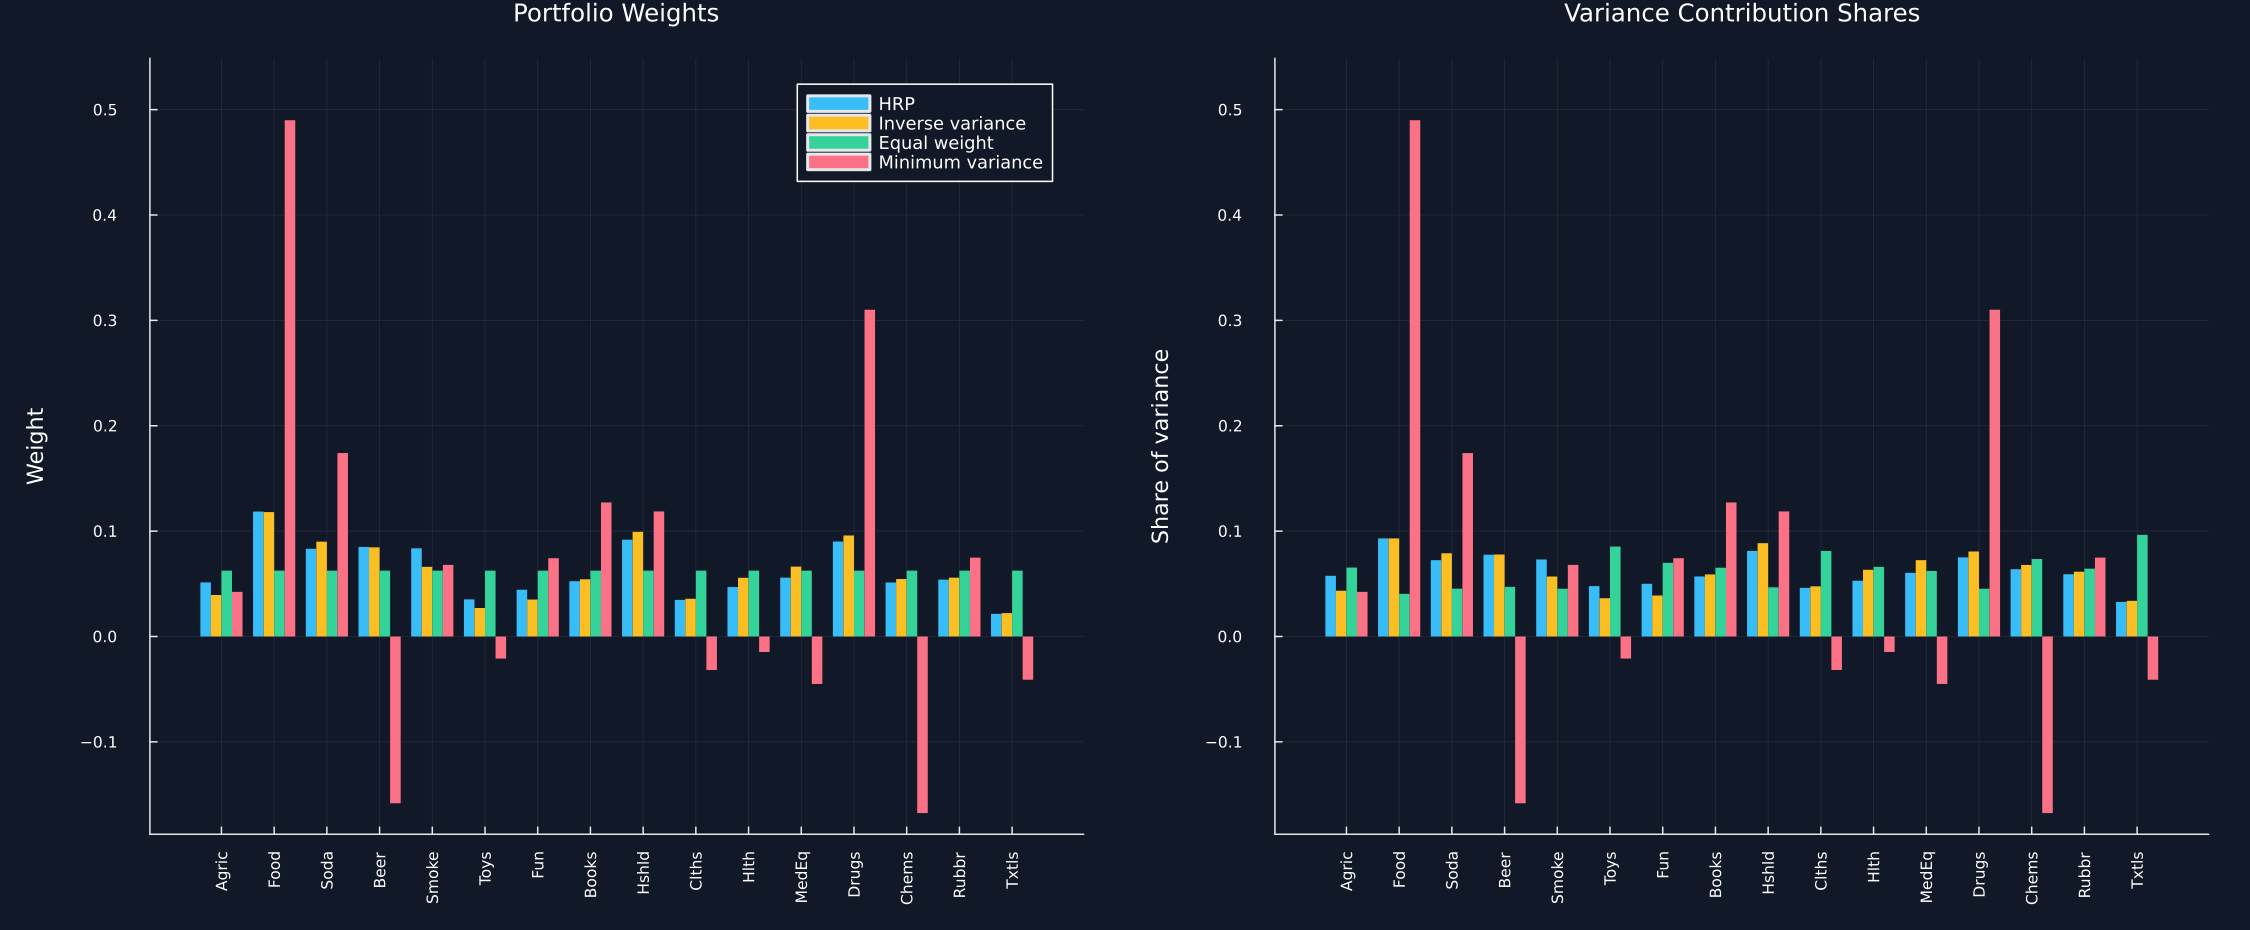

In [3]:
risk_rows = NamedTuple[]
for method in method_names
    weights = fitted_map[method]
    contribution = weights.*(annual_covariance*weights)
    fraction = contribution/sum(contribution)
    append!(risk_rows,[(Portfolio=method,Industry=selected_assets[i],Weight=weights[i],share=fraction[i]) for i in 1:16])
end
risk_contributions = DataFrame(risk_rows)
rename!(risk_contributions,:share=>"Variance contribution share")
risk_summary = DataFrame([(Portfolio=method,largest=maximum(risk_contributions[risk_contributions.Portfolio.==method,4]),smallest=minimum(risk_contributions[risk_contributions.Portfolio.==method,4]),total=sum(risk_contributions[risk_contributions.Portfolio.==method,4])) for method in sort(method_names)])
rename!(risk_summary,["Portfolio","Largest contribution share","Smallest contribution share","Contribution shares sum"])
table(risk_contributions,"risk_contributions","Asset weights and variance-contribution shares.")
table(risk_summary,"risk_contribution_summary","Portfolio variance-contribution summaries.")
p1 = plot(;title="Portfolio Weights",ylabel="Weight",legend=:topright)
p2 = plot(;title="Variance Contribution Shares",ylabel="Share of variance",legend=false)
for (position,(method,color)) in enumerate(zip(method_names,method_colors))
    x = collect(1:16).+(position-2.5)*0.2
    bar!(p1,x,fitted_map[method];bar_width=0.2,color,linealpha=0,label=method)
    bar!(p2,x,risk_contributions[risk_contributions.Portfolio.==method,4];bar_width=0.2,color,linealpha=0,label=method)
end
for panel in [p1,p2]
    plot!(panel;xticks=(1:16,selected_assets),xrotation=90,tickfontsize=7)
end
plot!(p1;ylims=(1.12*minimum(vcat(values(fitted_map)...)),1.12*maximum(vcat(values(fitted_map)...))))
plot!(p2;ylims=(1.12*minimum(risk_contributions[!,4]),1.12*maximum(risk_contributions[!,4])))
save_figure(plot(p1,p2;layout=(1,2),size=(1500,620)),paths,"portfolio_weights_risk_contributions")


## Checking allocation under singular covariance

A covariance matrix is singular when at least one eigenvalue is zero:

$$
\det(\Sigma)=\prod_{k=1}^{N}\lambda_k=0.
$$

Here, $\Sigma$ is the covariance matrix, $\det(\Sigma)$ is its determinant, $\lambda_k$ is eigenvalue $k$, and $N$ is the number of assets; covariance inversion then fails, while recursive bisection can still use cluster variances.

Row,Check,Value
,String,Float64
1,Released HRP equals traced bisection,4.16334e-17
2,Released HRP equals direct bisection,0.0
3,Cluster variance equals direct product,0.0
4,Singular covariance rank,7.0
5,Singular HRP budget,1.0
6,Slight asymmetry budget,1.0
7,One-asset bisection budget,1.0


Row,Quantity,Value
,String,Float64
1,Singular assets,8.0
2,Singular rank,7.0
3,Smallest eigenvalue,1.87702e-18
4,Largest eigenvalue,0.290573
5,Largest singular-case HRP weight,0.21289
6,Smallest singular-case HRP weight,0.0673534


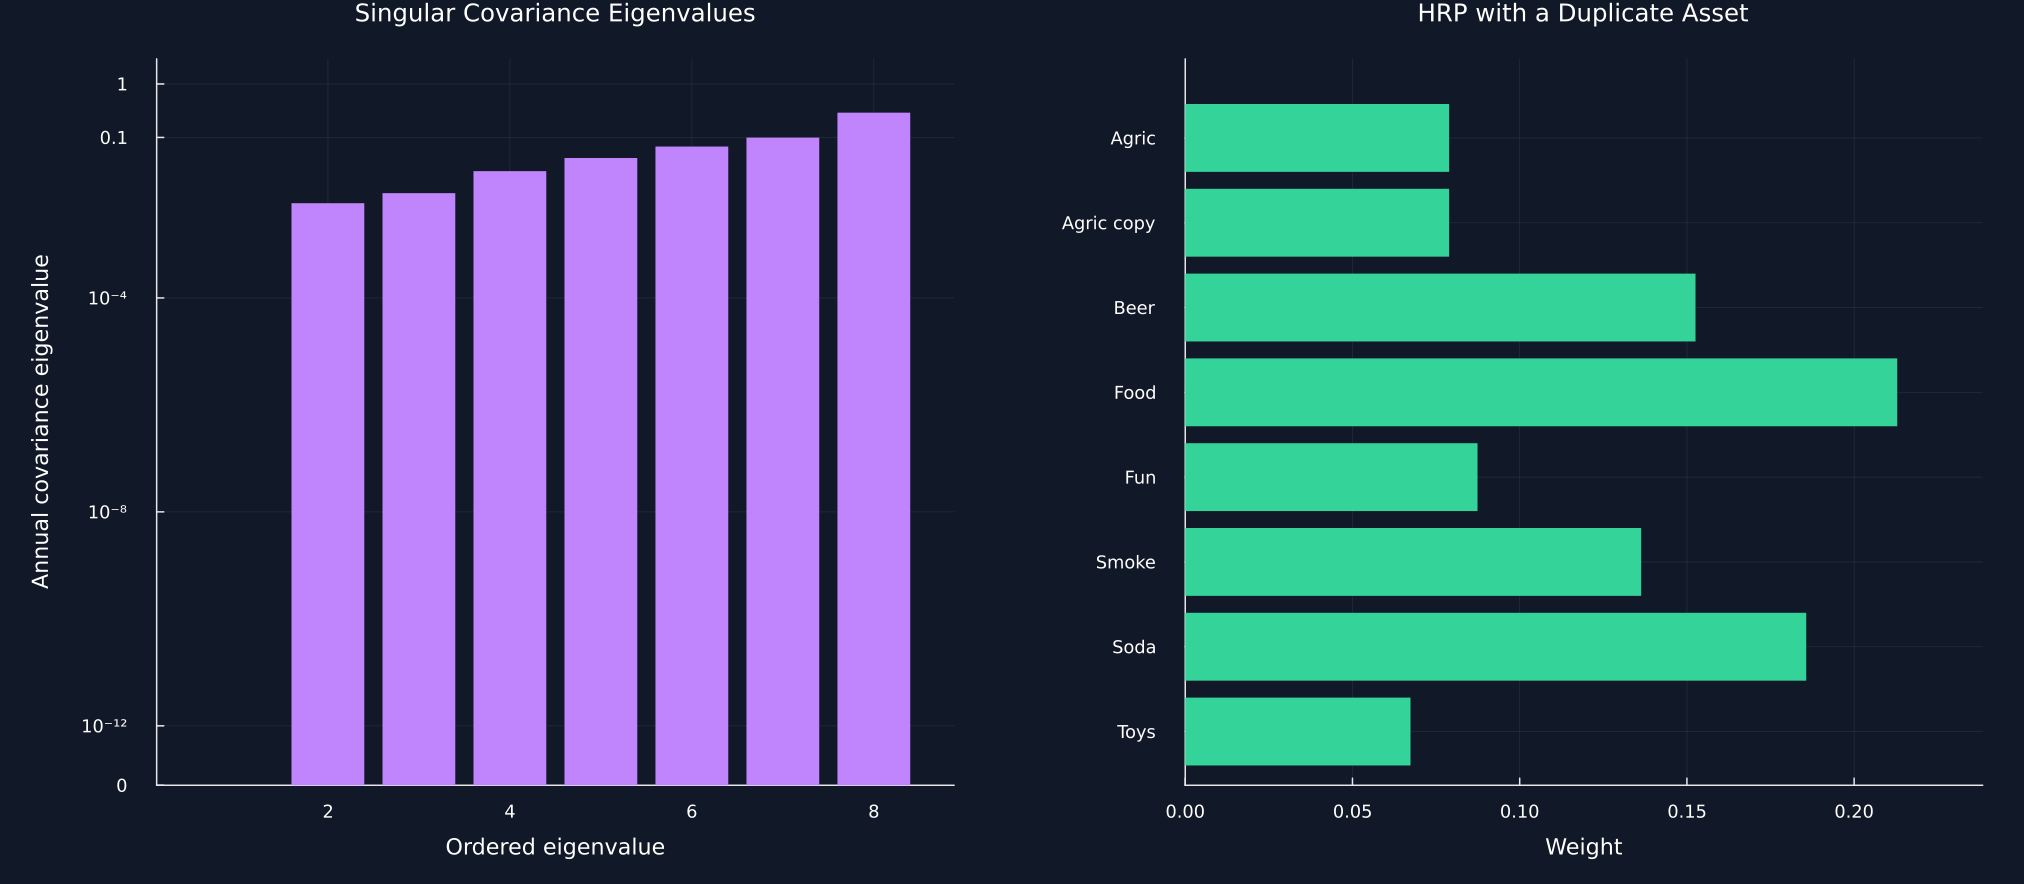

Row,Quantity,Value
,String,Float64
1,Assets,16.0
2,Recursive splits,15.0
3,HRP budget,1.0
4,Minimum HRP weight,0.0215049
5,Maximum HRP weight,0.11856
6,Public HRP annual volatility,0.16989
7,Singular example rank,7.0


In [4]:
duplicate_returns = hcat(public_sample[:,1:7],public_sample[:,1])
duplicate_names = vcat(selected_assets[1:7],selected_assets[1]*" copy")
singular_covariance = cov(duplicate_returns)*252
singular_correlation = cor(duplicate_returns)
singular_weights = hrp(singular_covariance,singular_correlation)
singular_eigenvalues = eigvals(Symmetric(singular_covariance))
asymmetric_correlation = copy(public_correlation)
asymmetric_correlation[1,2] += 1e-15
asymmetric_weights = hrp(annual_covariance,asymmetric_correlation)
one_asset_weights = recursive_bisection(annual_covariance[1:1,1:1],[1])
direct_cluster = annual_covariance[single_order[1:4],single_order[1:4]]
direct_internal = inverse_variance_weights(direct_cluster)
direct_variance = dot(direct_internal,direct_cluster*direct_internal)
released_variance = cluster_variance(annual_covariance,single_order[1:4])
calculation_checks = DataFrame("Check"=>["Released HRP equals traced bisection","Released HRP equals direct bisection","Cluster variance equals direct product","Singular covariance rank","Singular HRP budget","Slight asymmetry budget","One-asset bisection budget"],"Value"=>[maximum(abs,released_weights-traced_weights),maximum(abs,released_weights-direct_weights),abs(released_variance-direct_variance),rank(singular_covariance),sum(singular_weights),sum(asymmetric_weights),sum(one_asset_weights)])
special_case_summary = DataFrame("Quantity"=>["Singular assets","Singular rank","Smallest eigenvalue","Largest eigenvalue","Largest singular-case HRP weight","Smallest singular-case HRP weight"],"Value"=>[8,rank(singular_covariance),minimum(singular_eigenvalues),maximum(singular_eigenvalues),maximum(singular_weights),minimum(singular_weights)])
table(calculation_checks,"released_calculation_checks","Checks of the released HRP calculations.")
table(special_case_summary,"singular_case_summary","Public duplicate-asset singular-covariance check.")
save_data(DataFrame(Industry=duplicate_names,Weight=singular_weights),paths,"singular_weights")
save_data(DataFrame(eigenvalue=singular_eigenvalues),paths,"singular_eigenvalues")
symlog(value) = value<=1e-12 ? value/1e-12*(10/9) : 10/9+log10(value/1e-12)
tick_values = [0.0,1e-12,1e-8,1e-4,1e-1,1.0]
p1 = bar(1:8,symlog.(max.(singular_eigenvalues,0));color=violet,linealpha=0,legend=false,title="Singular Covariance Eigenvalues",xlabel="Ordered eigenvalue",ylabel="Annual covariance eigenvalue",yticks=(symlog.(tick_values),["0","10⁻¹²","10⁻⁸","10⁻⁴","0.1","1"]),ylims=(0,1.08*symlog(maximum(singular_eigenvalues))))
duplicate_sort = sortperm(duplicate_names)
p2 = bar(1:8,singular_weights[duplicate_sort];orientation=:h,yflip=true,yticks=(1:8,duplicate_names[duplicate_sort]),color=palette.green,linealpha=0,legend=false,title="HRP with a Duplicate Asset",xlabel="Weight",xlims=(0,1.12*maximum(singular_weights)))
save_figure(plot(p1,p2;layout=(1,2),size=(1350,590)),paths,"singular_covariance_hrp")
allocation_section_summary = DataFrame("Quantity"=>["Assets","Recursive splits","HRP budget","Minimum HRP weight","Maximum HRP weight","Public HRP annual volatility","Singular example rank"],"Value"=>[16,nrow(branch_allocations),sum(released_weights),minimum(released_weights),maximum(released_weights),portfolio_summary[1,2],rank(singular_covariance)])
table(allocation_section_summary,"allocation_section_summary","Section 21.2 numerical summary.")


## Tests

In [5]:
@assert nrow(branch_allocations)==15
@assert all(0 .<=branch_allocations[!,9].<=1)
@assert all(0 .<=branch_allocations[!,10].<=1)
@assert branch_allocations[!,9]+branch_allocations[!,10]≈ones(15)
@assert released_weights≈traced_weights
@assert released_weights≈direct_weights
@assert sum(released_weights)≈1
@assert all(released_weights.>=0)
@assert sum(fitted_map["Inverse variance"])≈1
@assert sum(fitted_map["Equal weight"])≈1
@assert sum(fitted_map["Minimum variance"])≈1
@assert released_variance≈direct_variance
@assert maximum(abs,risk_summary[!,4].-1)<1e-10
@assert rank(singular_covariance)<8
@assert minimum(singular_eigenvalues)<1e-12
@assert sum(singular_weights)≈1
@assert all(singular_weights.>=0)
@assert asymmetric_correlation!=asymmetric_correlation'
@assert sum(asymmetric_weights)≈1
@assert only(one_asset_weights)≈1
@assert isfile(joinpath(paths.figures,"ordered_covariance_hrp_weights.pdf"))
@assert isfile(joinpath(paths.figures,"recursive_split_diagnostics.pdf"))
@assert isfile(joinpath(paths.figures,"portfolio_weights_risk_contributions.pdf"))
@assert isfile(joinpath(paths.figures,"singular_covariance_hrp.pdf"))
@assert isfile(joinpath(paths.tables,"branch_allocations.tex"))
@assert isfile(joinpath(paths.tables,"released_calculation_checks.tex"))
